In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Churn distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [3]:
# Calculate churn percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

# Overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Overall churn rate: 26.54%


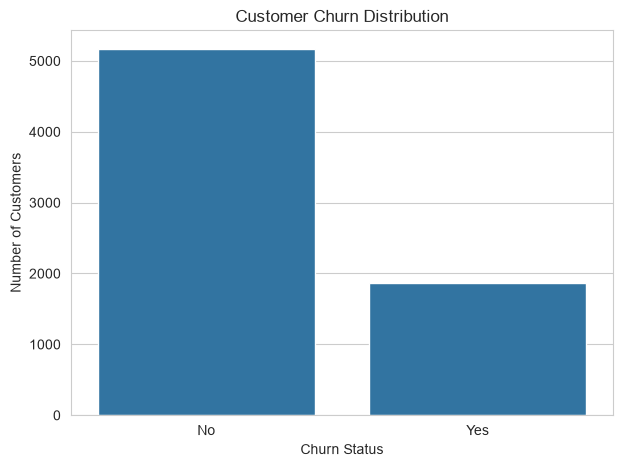

In [4]:
# Visualize the number of customers who stayed and left
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

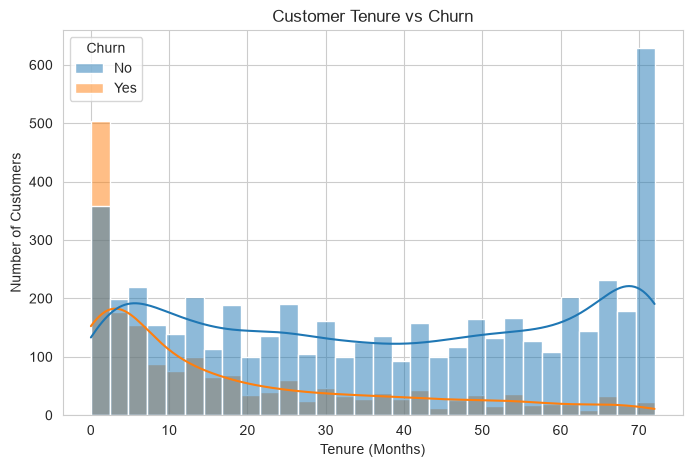

In [5]:
# Compare customer tenure between customers who stayed and left
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    kde=True
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

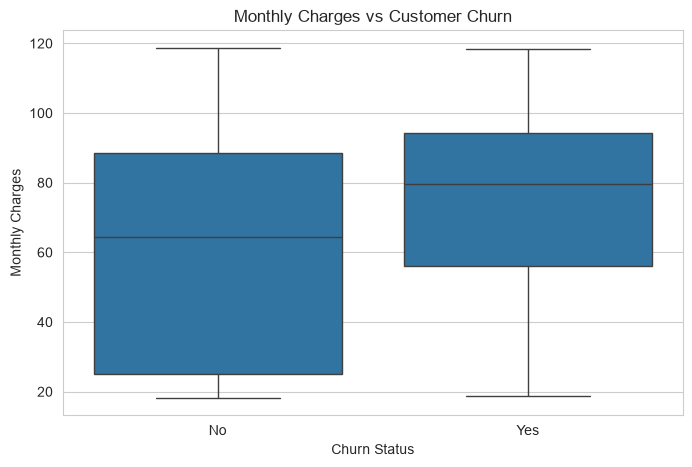

In [6]:
# Compare monthly charges for customers who stayed and left
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.show()

In [7]:
# Check data types, missing values, and duplicate rows
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
# Convert TotalCharges to numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [9]:
# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"]).copy()

print("Dataset shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Dataset shape after cleaning: (7032, 21)
Total missing values: 0


In [11]:
# Remove the customer identifier
df = df.drop(columns=["customerID"])

print("Final dataset shape:", df.shape)

Final dataset shape: (7032, 20)


In [12]:
# Separate input features and target variable
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (7032, 19)
Target shape: (7032,)

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [13]:
# Identify categorical and numerical features
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\saiki\AppData\Local\Temp\ipykernel_12036\587416900.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [14]:
# Convert categorical features into numerical columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

print("Encoded features shape:", X_encoded.shape)
print(X_encoded.head())

Encoded features shape: (7032, 30)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85            0   
1              0      34           56.95       1889.50            1   
2              0       2           53.85        108.15            1   
3              0      45           42.30       1840.75            1   
4              0       2           70.70        151.65            0   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0            1               0                 0   
1            0               0                 1   
2            0               0                 1   
3            0               0                 0   
4            0               0                 1   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                               1                  0  ...   
1                               0                  0  ...   
2                               0         

In [15]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 30)
Testing features: (1407, 30)
Training target: (5625,)
Testing target: (1407,)


In [16]:
# Train a Logistic Regression classification model
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


C:\Users\saiki\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [17]:
# Scale features and train Logistic Regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

model_lr.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [18]:
# Predict churn and calculate model accuracy
from sklearn.metrics import accuracy_score

y_pred_lr = model_lr.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%")

Logistic Regression Accuracy: 80.38%


In [19]:
# Evaluate precision, recall, and F1-score
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Stayed", "Churned"]
))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



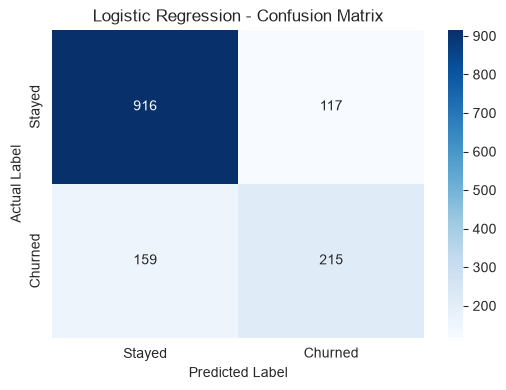

Confusion matrix:
 [[916 117]
 [159 215]]


In [20]:
# Visualize correct and incorrect predictions
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion matrix:\n", cm)

In [21]:
# Store Logistic Regression accuracy
results = {
    "Logistic Regression": accuracy_lr * 100
}

print(results)

{'Logistic Regression': 80.38379530916845}


In [22]:
# Train a Random Forest classification model
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model_rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
# Predict churn using Random Forest
y_pred_rf = model_rf.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

First 10 actual values:
[0 0 0 1 0 1 0 0 1 0]

First 10 predicted values:
[0 1 0 0 0 0 0 0 1 0]


In [24]:
# Evaluate Random Forest performance
from sklearn.metrics import accuracy_score, classification_report

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Churned"]
))

Random Forest Accuracy: 76.83%

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.87      0.81      0.84      1033
     Churned       0.55      0.65      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407



In [25]:
# Compare Logistic Regression and Random Forest
results = {
    "Logistic Regression": accuracy_lr * 100,
    "Random Forest": accuracy_rf * 100
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy (%)"]
)

print(results_df)

                 Model  Accuracy (%)
0  Logistic Regression     80.383795
1        Random Forest     76.830135


In [28]:
# Compare both trained models using key evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Churn Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "Churn F1-Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
})

print(comparison.round(3))

                 Model  Accuracy  Churn Precision  Churn Recall  \
0  Logistic Regression     0.804            0.648         0.575   
1        Random Forest     0.768            0.555         0.652   

   Churn F1-Score  
0           0.609  
1           0.600  


In [29]:
# Train a class-weighted Logistic Regression model
model_lr_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

model_lr_balanced.fit(X_train, y_train)

y_pred_balanced = model_lr_balanced.predict(X_test)

print("Balanced Logistic Regression")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Stayed", "Churned"]
))

Balanced Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.91      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [30]:
# Identify features with the strongest Logistic Regression coefficients
lr_model = model_lr.named_steps["logisticregression"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lr_model.coef_[0]
})

feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print(feature_importance.head(10))

                           Feature  Coefficient  Absolute Coefficient
1                           tenure    -1.347613              1.347613
2                   MonthlyCharges    -0.851551              0.851551
10     InternetService_Fiber optic     0.727745              0.727745
3                     TotalCharges     0.639028              0.639028
25               Contract_Two year    -0.602591              0.602591
24               Contract_One year    -0.310898              0.310898
21                 StreamingTV_Yes     0.249702              0.249702
23             StreamingMovies_Yes     0.236368              0.236368
9                MultipleLines_Yes     0.214359              0.214359
28  PaymentMethod_Electronic check     0.181473              0.181473


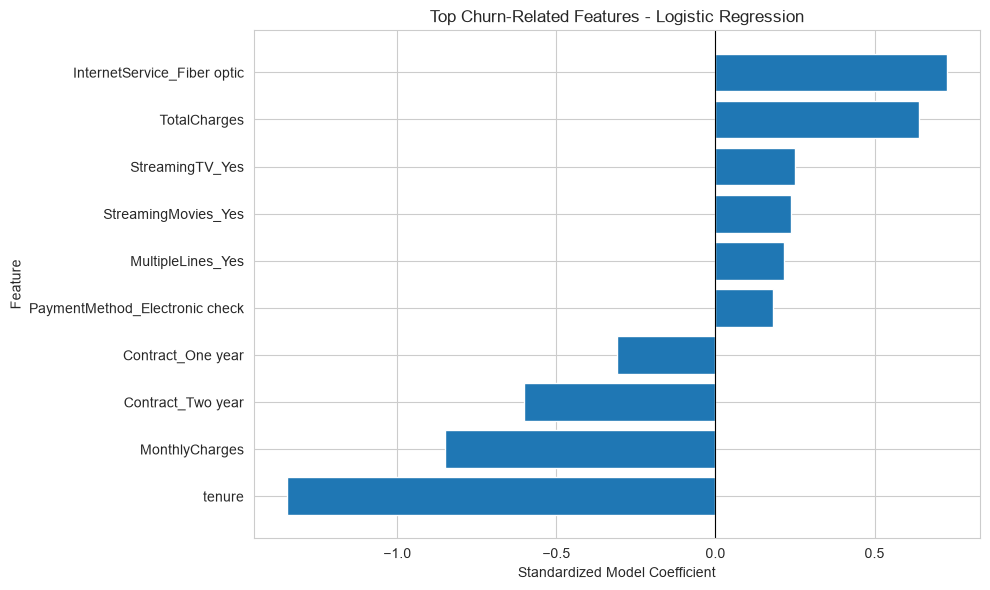

In [31]:
# Plot the ten features with the largest absolute coefficients
top_features = feature_importance.head(10).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top Churn-Related Features - Logistic Regression")
plt.xlabel("Standardized Model Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [32]:
# Compare actual and predicted churn for sample customers
sample_results = pd.DataFrame({
    "Actual Churn": y_test.iloc[:10].map({0: "No", 1: "Yes"}).values,
    "Predicted Churn": pd.Series(y_pred_lr[:10]).map({0: "No", 1: "Yes"}).values
})

print(sample_results)

  Actual Churn Predicted Churn
0           No              No
1           No             Yes
2           No              No
3          Yes              No
4           No              No
5          Yes              No
6           No              No
7           No              No
8          Yes             Yes
9           No              No


In [33]:
# Display churn probabilities for sample test customers
churn_probabilities = model_lr.predict_proba(X_test.iloc[:10])[:, 1]

probability_results = pd.DataFrame({
    "Predicted Churn Probability (%)": (churn_probabilities * 100).round(2),
    "Predicted Churn": pd.Series(y_pred_lr[:10]).map({0: "No", 1: "Yes"}).values
})

print(probability_results)

   Predicted Churn Probability (%) Predicted Churn
0                             1.71              No
1                            59.61             Yes
2                             0.48              No
3                            20.00              No
4                            10.02              No
5                            47.00              No
6                             2.66              No
7                            16.41              No
8                            68.61             Yes
9                             1.52              No


In [35]:
# Compare performance metrics for all three models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Balanced Logistic Regression": y_pred_balanced
}

final_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Churn Precision": round(precision_score(y_test, pred), 3),
        "Churn Recall": round(recall_score(y_test, pred), 3),
        "Churn F1-Score": round(f1_score(y_test, pred), 3)
    }
    for name, pred in predictions.items()
])

print(final_comparison)

                          Model  Accuracy  Churn Precision  Churn Recall  \
0           Logistic Regression     0.804            0.648         0.575   
1                 Random Forest     0.768            0.555         0.652   
2  Balanced Logistic Regression     0.726            0.491         0.797   

   Churn F1-Score  
0           0.609  
1           0.600  
2           0.608  


In [36]:
# Compare ROC-AUC scores for all three models
from sklearn.metrics import roc_auc_score

probabilities = {
    "Logistic Regression": model_lr.predict_proba(X_test)[:, 1],
    "Random Forest": model_rf.predict_proba(X_test)[:, 1],
    "Balanced Logistic Regression": model_lr_balanced.predict_proba(X_test)[:, 1]
}

auc_comparison = pd.DataFrame([
    {
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_test, prob), 3)
    }
    for name, prob in probabilities.items()
])

print(auc_comparison.sort_values(by="ROC-AUC", ascending=False))

                          Model  ROC-AUC
0           Logistic Regression    0.836
2  Balanced Logistic Regression    0.835
1                 Random Forest    0.821


In [37]:
# Create the final model evaluation summary
final_summary = final_comparison.merge(
    auc_comparison,
    on="Model"
)

final_summary = final_summary.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print(final_summary)

                          Model  Accuracy  Churn Precision  Churn Recall  \
0           Logistic Regression     0.804            0.648         0.575   
1  Balanced Logistic Regression     0.726            0.491         0.797   
2                 Random Forest     0.768            0.555         0.652   

   Churn F1-Score  ROC-AUC  
0           0.609    0.836  
1           0.608    0.835  
2           0.600    0.821  


In [38]:
# Save the final model comparison results
final_summary.to_csv("customer_churn_model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!
